# Tetoronom 데이터 구조 분석 노트북

## 목적
- CSV 데이터 구조(컬럼, 센서별 row 구조, 타임스탬프) 파악
- **센서 제약 사항 검증**: foot/hip 센서에 별도 가속도계 데이터가 있는지 확인
- 케이던스 계산에 적합한 segment 결정
- 충격량 분석을 위한 segment별 특성 파악

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import signal
import os, warnings
warnings.filterwarnings('ignore')

# 한글 폰트 설정
def setup_korean_font():
    candidates = ['Apple SD Gothic Neo', 'AppleGothic', 'Nanum Gothic', 'NanumGothic']
    available = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in available:
            matplotlib.rcParams['font.family'] = name
            matplotlib.rcParams['axes.unicode_minus'] = False
            return name
    return 'DejaVu Sans'

FONT = setup_korean_font()
print(f'사용 폰트: {FONT}')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#F8F9FA'

사용 폰트: Apple SD Gothic Neo


## 1. 파일 목록 확인

In [2]:
DATA_DIR = '../data'

files = []
for root, dirs, fnames in os.walk(DATA_DIR):
    for f in fnames:
        if f.endswith('.csv'):
            files.append(os.path.relpath(os.path.join(root, f), DATA_DIR))

files.sort()
print(f'총 {len(files)}개 CSV 파일:')
for f in files:
    fpath = os.path.join(DATA_DIR, f)
    sz = os.path.getsize(fpath) / 1024
    print(f'  {f}  ({sz:.0f} KB)')

총 12개 CSV 파일:
  박민규/박민규_control.csv  (18415 KB)
  박민규/박민규_tape.csv  (17818 KB)
  박민규/박민규_tape_metro.csv  (18756 KB)
  이상희/이상희_control.csv  (19563 KB)
  이상희/이상희_metro.csv  (18766 KB)
  이상희/이상희_tape.csv  (19549 KB)
  이상희/이상희_tape_metro.csv  (19556 KB)
  진현준/current_unsaved_log-gait-cycle-analysis.csv  (25 KB)
  진현준/진현준_control.csv  (19510 KB)
  진현준/진현준_metro.csv  (18631 KB)
  진현준/진현준_tape.csv  (19507 KB)
  진현준/진현준_tape_metro.csv  (19500 KB)


## 2. 샘플 파일 로드 및 기본 정보

In [3]:
SAMPLE = '../data/진현준/진현준_control.csv'
df = pd.read_csv(SAMPLE)
df['iso_time'] = pd.to_datetime(df['iso_time'])

print(f'Shape: {df.shape}')
print(f'컬럼 수: {len(df.columns)}')
print(f'\nsource_segment 분포:')
print(df['source_segment'].value_counts())
print(f'\n측정 시간: {(df.iso_time.max() - df.iso_time.min()).total_seconds():.1f}초')

Shape: (21725, 59)
컬럼 수: 59

source_segment 분포:
source_segment
shank    7243
foot     7241
hip      7241
Name: count, dtype: int64

측정 시간: 120.7초


In [4]:
pd.DataFrame(df.columns)


,0
0,iso_time
1,session_name
2,source_segment
3,ankle_dorsiflexion_plantarflexion_deg
4,ankle_inversion_eversion_deg
5,hip_quaternion_pitch_deg
6,hip_quaternion_roll_deg
7,torso_pitch_deg
8,torso_roll_deg
9,ankle_dorsiflexion_plantarflexion_unfiltered_deg


## 3. 센서 제약 사항 검증

### 질문: foot 센서와 hip 센서에 별도의 가속도계 데이터가 있는가?

데이터에서 `shank_free_acceleration_*` 외에 `foot_free_acceleration_*` 또는 `hip_free_acceleration_*` 컬럼이 있는지 확인합니다.

In [5]:
acc_cols = [c for c in df.columns if 'acceleration' in c.lower() or 'acc' in c.lower()]

print('=== 가속도계 관련 컬럼 ===')  
for c in acc_cols:
    print(f'  {c}')

print()
print('결론:')
has_foot_acc = any('foot' in c and 'acceleration' in c for c in df.columns)
has_hip_acc  = any('hip' in c and 'acceleration' in c for c in df.columns)
print(f'  foot 가속도 컬럼 존재: {has_foot_acc}')
print(f'  hip 가속도 컬럼 존재:  {has_hip_acc}')
print(f'  shank 가속도만 존재: {not has_foot_acc and not has_hip_acc}')

=== 가속도계 관련 컬럼 ===
  shank_free_acceleration_x_m_s2
  shank_free_acceleration_y_m_s2
  shank_free_acceleration_z_m_s2
  shank_free_acceleration_resultant_m_s2

결론:
  foot 가속도 컬럼 존재: False
  hip 가속도 컬럼 존재:  False
  shank 가속도만 존재: True


In [6]:
# segment별 shank_free_acceleration 값이 동일한지 확인
print('=== 동일 타임스탬프에서 segment별 shank_free_acc_z 값 비교 ===')
print('(동일하면 → broadcast된 단일 센서 값)')
print()

for seg in ['foot', 'shank', 'hip']:
    sub = df[df['source_segment'] == seg].head(3)
    print(f'--- {seg} (첫 3행) ---')
    print(sub[['iso_time', 'shank_free_acceleration_z_m_s2']].to_string(index=False))
    print()

print('⚠ 각 segment row의 iso_time이 다르므로,')
print('  같은 타임스탬프가 아닌 각자 다른 시점의 shank 센서 값을 담고 있습니다.')
print('  즉, shank 가속도는 단 하나의 센서에서만 수집되며,')
print('  foot/hip row는 해당 시점에 기록된 shank 가속도 샘플을 공유합니다.')

=== 동일 타임스탬프에서 segment별 shank_free_acc_z 값 비교 ===
(동일하면 → broadcast된 단일 센서 값)

--- foot (첫 3행) ---
                        iso_time  shank_free_acceleration_z_m_s2
2026-05-20 05:30:36.258000+00:00                       12.573404
2026-05-20 05:30:36.259000+00:00                       12.573404
2026-05-20 05:30:36.277000+00:00                       17.499485

--- shank (첫 3행) ---
                        iso_time  shank_free_acceleration_z_m_s2
2026-05-20 05:30:36.256000+00:00                       12.573404
2026-05-20 05:30:36.275000+00:00                       44.213699
2026-05-20 05:30:36.276000+00:00                       17.499485

--- hip (첫 3행) ---
                        iso_time  shank_free_acceleration_z_m_s2
2026-05-20 05:30:36.273000+00:00                       12.573404
2026-05-20 05:30:36.293000+00:00                       17.499485
2026-05-20 05:30:36.303000+00:00                       17.499485

⚠ 각 segment row의 iso_time이 다르므로,
  같은 타임스탬프가 아닌 각자 다른 시점의 shank 센서 값을 담고 있습니다.

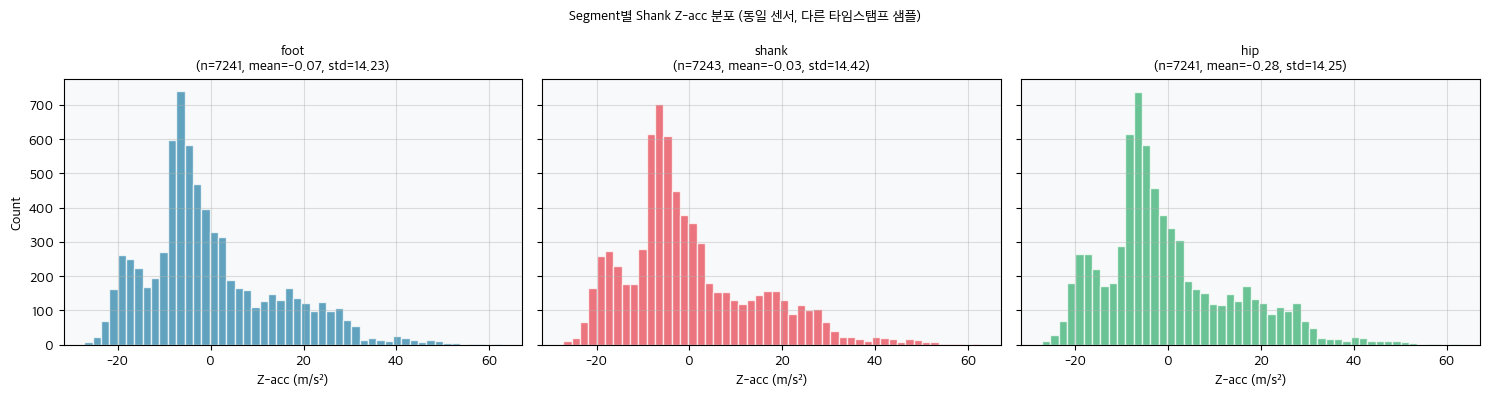

In [7]:
# 각 segment별 shank_free_acc_z 분포 비교
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
fig.suptitle('Segment별 Shank Z-acc 분포 (동일 센서, 다른 타임스탬프 샘플)',
             fontproperties=fm.FontProperties(family=FONT))

segs = ['foot', 'shank', 'hip']
colors = ['#2E86AB', '#E84855', '#3BB273']
for ax, seg, color in zip(axes, segs, colors):
    sub = df[df['source_segment'] == seg]
    z = sub['shank_free_acceleration_z_m_s2'].values
    ax.hist(z, bins=50, color=color, alpha=0.75, edgecolor='white')
    ax.set_title(f'{seg}\n(n={len(z)}, mean={np.mean(z):.2f}, std={np.std(z):.2f})',
                fontproperties=fm.FontProperties(family=FONT))
    ax.set_xlabel('Z-acc (m/s²)', fontproperties=fm.FontProperties(family=FONT))
    ax.grid(alpha=0.4)
axes[0].set_ylabel('Count', fontproperties=fm.FontProperties(family=FONT))
plt.tight_layout()
plt.show()

### 검증 결론

| 센서 | 가속도계 데이터 | 각도(quaternion) 데이터 |
|------|:--------------:|:--------------------:|
| shank IMU | ✅ `shank_free_acceleration_{x,y,z,resultant}` | ✅ shank_quaternion_* |
| foot IMU  | ❌ 없음 | ✅ ankle_dorsiflexion_plantarflexion_deg 등 |
| hip IMU   | ❌ 없음 | ✅ hip_quaternion_pitch/roll_deg 등 |

**원인**: 이 실험에 사용된 IMU 앱은 shank 센서의 가속도만 수집합니다.  
foot과 hip row에 `shank_free_acceleration` 값이 있는 것은 **동일 센서 값을 각 row에 broadcast**한 것입니다.  
각 row의 타임스탬프가 달라 실질적으로 서로 다른 시점의 shank 샘플을 담습니다.

## 4. 케이던스 계산 방법 비교

In [8]:
FS = 60.0; GRAVITY = 9.81

foot_df  = df[df['source_segment'] == 'foot'].sort_values('iso_time').reset_index(drop=True)
shank_df = df[df['source_segment'] == 'shank'].sort_values('iso_time').reset_index(drop=True)

def cadence_from(seg_df, label):
    res = seg_df['shank_free_acceleration_resultant_m_s2'].values
    peaks, _ = signal.find_peaks(res, height=2*GRAVITY, distance=int(FS*0.25), prominence=3.0)
    dur = len(res)/FS
    cad = len(peaks)/dur*60
    print(f'{label}: {len(peaks)} peaks in {dur:.1f}s → cadence = {cad:.1f} steps/min')
    return peaks, cad

peaks_foot,  cad_foot  = cadence_from(foot_df,  'foot  rows')
peaks_shank, cad_shank = cadence_from(shank_df, 'shank rows')

print(f'\n실험 기록 케이던스 (진현준 control): 186 steps/min')
print(f'foot rows:  오차 {abs(cad_foot - 186):.1f}')
print(f'shank rows: 오차 {abs(cad_shank - 186):.1f}')

foot  rows: 358 peaks in 120.7s → cadence = 178.0 steps/min
shank rows: 371 peaks in 120.7s → cadence = 184.4 steps/min

실험 기록 케이던스 (진현준 control): 186 steps/min
foot rows:  오차 8.0
shank rows: 오차 1.6


## 5. Segment별 충격량 특성

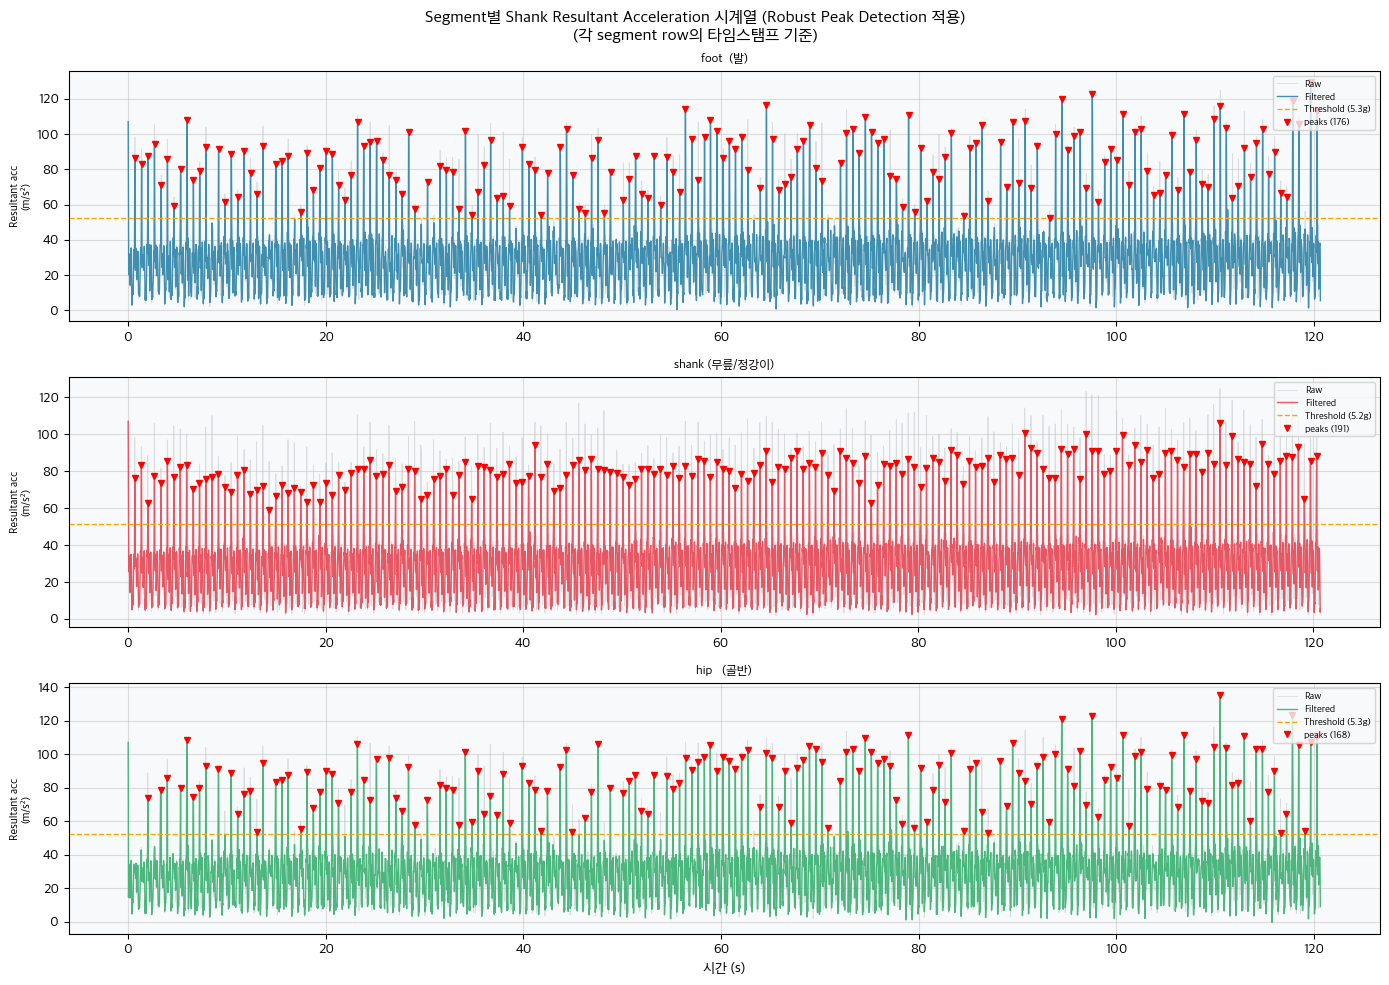

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
fig.suptitle('Segment별 Shank Resultant Acceleration 시계열 (Robust Peak Detection 적용)\n(각 segment row의 타임스탬프 기준)',
            fontproperties=fm.FontProperties(family=FONT, size=12))

segs_data = {
    'foot  (발)':  df[df['source_segment']=='foot'].sort_values('iso_time'),
    'shank (무릎/정강이)': df[df['source_segment']=='shank'].sort_values('iso_time'),
    'hip   (골반)': df[df['source_segment']=='hip'].sort_values('iso_time'),
}
colors_seg = ['#2E86AB', '#E84855', '#3BB273']

from scipy import signal
# 필터 설정
GRAVITY = 9.81
FS = 60.0
nyq = 0.5 * FS
normal_cutoff = 15.0 / nyq
b, a = signal.butter(4, normal_cutoff, btype='low', analog=False)
min_dist_ms = 280.0

for ax, (label, sub), color in zip(axes, segs_data.items(), colors_seg):
    t = np.arange(len(sub)) / FS
    raw_acc = sub['shank_free_acceleration_resultant_m_s2'].values
    
    # 1. 신호 스무딩
    smoothed = signal.filtfilt(b, a, raw_acc)
    
    # 2. 동적 임계값 설정
    mean_val = np.mean(smoothed)
    std_val = np.std(smoothed)
    dynamic_height = max(1.5 * GRAVITY, mean_val + 1.2 * std_val)
    dynamic_prominence = max(0.5 * GRAVITY, std_val * 0.5)
    
    # 3. Peak 감지
    peaks, _ = signal.find_peaks(
        smoothed,
        height=dynamic_height,
        distance=int(FS * min_dist_ms / 1000.0),
        prominence=dynamic_prominence,
    )
    
    # 시각화: 원본은 회색으로 옅게, 필터된 신호는 자기 색깔로 진하게
    ax.plot(t, raw_acc, color='#BDC3C7', linewidth=0.6, alpha=0.5, label='Raw')
    ax.plot(t, smoothed, color=color, linewidth=1.0, alpha=0.9, label='Filtered')
    
    ax.axhline(dynamic_height, color='orange', linestyle='--', linewidth=1, label=f'Threshold ({dynamic_height/9.81:.1f}g)')
    
    ax.plot(t[peaks], smoothed[peaks], 'rv', markersize=5, label=f'peaks ({len(peaks)})')
    
    ax.set_title(label, fontproperties=fm.FontProperties(family=FONT, size=9))
    ax.set_ylabel('Resultant acc\n(m/s²)', fontsize=8)
    ax.legend(fontsize=7, prop=fm.FontProperties(family=FONT, size=7), loc='upper right')
    ax.grid(alpha=0.4)

axes[-1].set_xlabel('시간 (s)', fontproperties=fm.FontProperties(family=FONT))
plt.tight_layout()
plt.show()


## 6. 각도 데이터 시각화

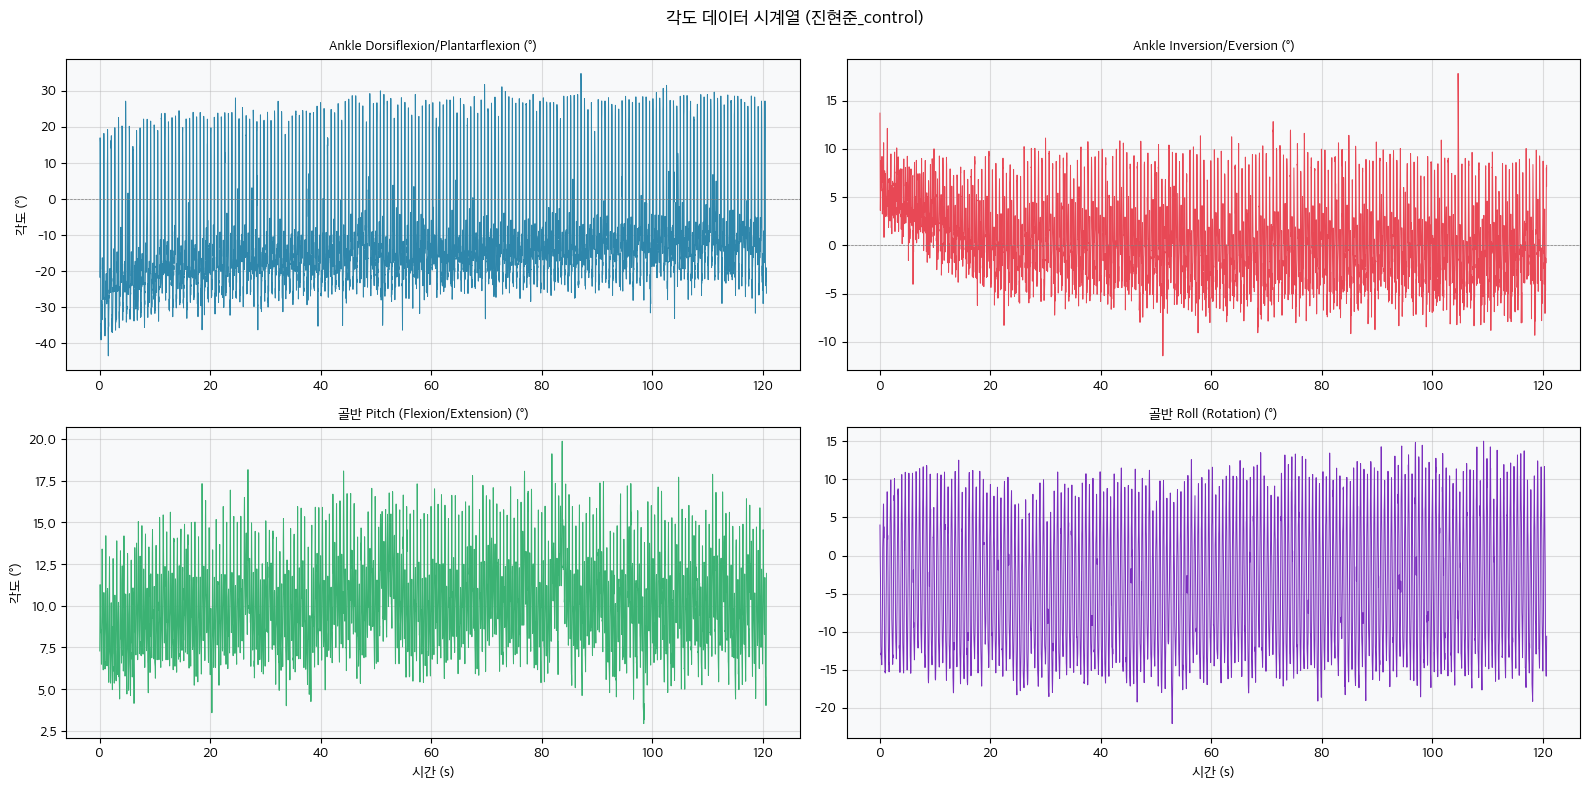

In [10]:
# Ankle & Hip angle time series
foot_sorted = df[df['source_segment']=='foot'].sort_values('iso_time')
hip_sorted  = df[df['source_segment']=='hip'].sort_values('iso_time')

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle('각도 데이터 시계열 (진현준_control)', 
             fontproperties=fm.FontProperties(family=FONT, size=13))

t_foot = np.arange(len(foot_sorted)) / FS
t_hip  = np.arange(len(hip_sorted))  / FS

# Ankle DF/PF
ax = axes[0, 0]
ax.plot(t_foot, foot_sorted['ankle_dorsiflexion_plantarflexion_deg'], 
        color='#2E86AB', linewidth=0.7)
ax.set_title('Ankle Dorsiflexion/Plantarflexion (°)', 
             fontproperties=fm.FontProperties(family=FONT))
ax.set_ylabel('각도 (°)', fontproperties=fm.FontProperties(family=FONT))
ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
ax.grid(alpha=0.4)

# Ankle Inv/Ev
ax = axes[0, 1]
ax.plot(t_foot, foot_sorted['ankle_inversion_eversion_deg'],
        color='#E84855', linewidth=0.7)
ax.set_title('Ankle Inversion/Eversion (°)', 
             fontproperties=fm.FontProperties(family=FONT))
ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
ax.grid(alpha=0.4)

# Hip pitch (Flex/Ext)
ax = axes[1, 0]
ax.plot(t_hip, hip_sorted['hip_quaternion_pitch_deg'],
        color='#3BB273', linewidth=0.7)
ax.set_title('골반 Pitch (Flexion/Extension) (°)', 
             fontproperties=fm.FontProperties(family=FONT))
ax.set_ylabel('각도 (°)', fontproperties=fm.FontProperties(family=FONT))
ax.set_xlabel('시간 (s)', fontproperties=fm.FontProperties(family=FONT))
ax.grid(alpha=0.4)

# Hip roll (Rotation)
ax = axes[1, 1]
ax.plot(t_hip, hip_sorted['hip_quaternion_roll_deg'],
        color='#7B2FBE', linewidth=0.7)
ax.set_title('골반 Roll (Rotation) (°)', 
             fontproperties=fm.FontProperties(family=FONT))
ax.set_xlabel('시간 (s)', fontproperties=fm.FontProperties(family=FONT))
ax.grid(alpha=0.4)

plt.tight_layout()
plt.show()

## 7. 모든 피험자-조건 파일 기본 통계

In [11]:
import glob

summary_rows = []
for csv_path in sorted(glob.glob('../data/**/*.csv', recursive=True)):
    fname = os.path.basename(csv_path)
    name, cond = fname.replace('.csv','').split('_', 1)
    try:
        df_tmp = pd.read_csv(csv_path)
        segments = dict(df_tmp['source_segment'].value_counts())
        z = df_tmp[df_tmp['source_segment']=='foot']['shank_free_acceleration_z_m_s2']
        summary_rows.append({
            '피험자': name, '조건': cond,
            'foot rows': segments.get('foot', 0),
            'shank rows': segments.get('shank', 0),
            'hip rows': segments.get('hip', 0),
            '총 rows': len(df_tmp),
            '측정시간(s)': round(len(df_tmp)/3/60, 1),
            'Z acc mean (foot)': round(z.mean(), 3),
            'Z acc std (foot)': round(z.std(), 3),
        })
    except Exception as e:
        print(f'오류: {csv_path}: {e}')

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

오류: ../data/진현준/current_unsaved_log-gait-cycle-analysis.csv: Error tokenizing data. C error: Expected 2 fields in line 28, saw 25

      피험자         조건  foot rows  shank rows  hip rows  총 rows  측정시간(s)  Z acc mean (foot)  Z acc std (foot)
 박민규    control       6838        6838      6839   20515    114.0             -0.372            15.529
 박민규       tape       6649        6649      6651   19949    110.8             -0.230            16.167
 박민규 tape_metro       6965        6965      6965   20895    116.1             -0.277            14.077
  이상희    control       7242        7243      7240   21725    120.7             -0.336            17.739
  이상희      metro       6950        6948      6950   20848    115.8             -0.408            18.523
  이상희       tape       7259        7260      7258   21777    121.0             -0.316            17.648
  이상희 tape_metro       7254        7253      7253   21760    120.9             -0.169            18.349
진혀

## 8. 데이터 구조 최종 요약

### 발견 사항

1. **데이터 형식**: 각 CSV는 foot/shank/hip 세 센서의 row가 혼합되어 있음 (long format)
2. **가속도 데이터**: `shank_free_acceleration_*` 컬럼만 존재. foot, hip에는 없음
3. **각도 데이터**: 
   - foot rows: `ankle_dorsiflexion_plantarflexion_deg`, `ankle_inversion_eversion_deg`
   - hip rows: `hip_quaternion_pitch_deg` (Flex/Ext), `hip_quaternion_roll_deg` (Rotation)
4. **타임스탬프**: 각 row는 고유한 iso_time을 가짐 (동일 타임스탬프에 여러 segment가 있지 않음)
5. **샘플링**: ~60 Hz

### 충격량 분석 전략

| 분석 부위 | 사용 데이터 | 해석 |
|-----------|------------|------|
| 발 (foot) | foot rows의 shank_free_acc | 발 센서 타임스탬프에서의 shank 충격 근사 |
| 무릎/정강이 (shank) | shank rows의 shank_free_acc | shank 센서 직접 측정 |
| 골반 (hip) | hip rows의 shank_free_acc | 골반 센서 타임스탬프에서의 shank 충격 근사 |

### 케이던스 계산
- foot rows의 shank_free_acceleration_resultant에서 peak detection 사용
- 착지(heel strike) 이벤트가 foot 타임스탬프에 더 잘 반영됨